# ML Zoomcamp 2026 — Homework 4: Evaluation

Dataset: `course_lead_scoring_2026.csv` (pinned 2026 release, same folder). Target: `converted`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

%matplotlib inline

## Data preparation
Categorical missing → `'NA'`, numerical missing → `0.0`.

In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [3]:
categorical = list(df.select_dtypes(include=['object', 'string']).columns)
numerical = [c for c in df.columns if c not in categorical and c != 'converted']
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
categorical, numerical

(['lead_source', 'industry', 'employment_status', 'location'],
 ['annual_income',
  'number_of_courses_viewed',
  'interaction_count',
  'lead_score'])

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train, df_val, df_test = [d.reset_index(drop=True) for d in (df_train, df_val, df_test)]

y_train, y_val, y_test = df_train.converted.values, df_val.converted.values, df_test.converted.values
for d in (df_train, df_val, df_test):
    del d['converted']

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Q1. ROC AUC feature importance
Use each numerical variable as the score; if AUC < 0.5, negate the variable.

In [5]:
aucs = {}
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    aucs[col] = auc
pd.Series(aucs).sort_values(ascending=False)

lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64

## Q2. Training the model

In [6]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    return dv, model

def predict(df, dv, model):
    X = dv.transform(df[categorical + numerical].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
round(roc_auc_score(y_val, y_pred), 3)

0.732

## Q3. Precision and recall
Thresholds 0.00 → 1.00, step 0.01. Skip thresholds where both metrics are 0, then pick the smallest |P − R|.

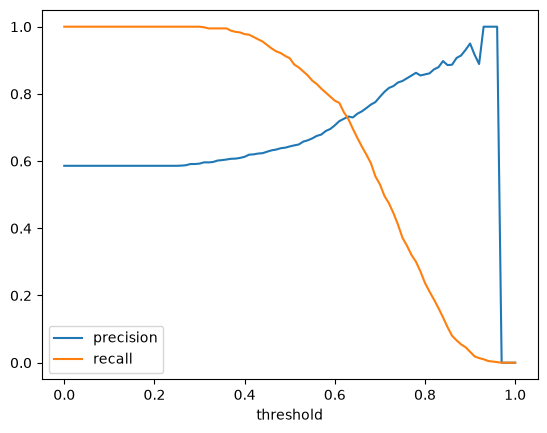

In [7]:
thresholds = np.round(np.arange(0.0, 1.01, 0.01), 2)
rows = []
for t in thresholds:
    pred = y_pred >= t
    tp = (pred & (y_val == 1)).sum()
    fp = (pred & (y_val == 0)).sum()
    fn = (~pred & (y_val == 1)).sum()
    p = tp / (tp + fp) if tp + fp > 0 else 0.0
    r = tp / (tp + fn) if tp + fn > 0 else 0.0
    rows.append((t, p, r))
df_scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall'])

plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold'); plt.legend();

In [8]:
valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
valid.sort_values('diff').head(3)

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629


## Q4. F1 score
$F_1 = 2PR/(P+R)$

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

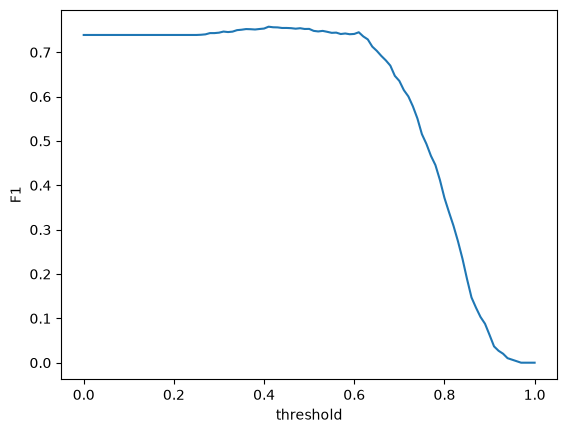

In [9]:
df_scores['f1'] = 2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall)
df_scores['f1'] = df_scores.f1.fillna(0)

plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold'); plt.ylabel('F1');

df_scores.loc[df_scores.f1.idxmax()]

## Q5. 5-fold CV

In [10]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]
    dv, model = train(df_tr, df_tr.converted.values)
    scores.append(roc_auc_score(df_va.converted.values, predict(df_va, dv, model)))

np.round(scores, 3), round(np.mean(scores), 3), round(np.std(scores), 3)

(array([0.731, 0.73 , 0.736, 0.741, 0.721]),
 np.float64(0.732),
 np.float64(0.007))

## Q6. Hyperparameter tuning

In [11]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        dv, model = train(df_tr, df_tr.converted.values, C=C)
        scores.append(roc_auc_score(df_va.converted.values, predict(df_va, dv, model)))
    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
